In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
import jax.numpy as jnp
import jax
from scipy.special import erfc, erfcinv
from functools import partial, wraps

from lib import neurons, input_gen, driver, utils

In [8]:
n_trials = 6
ns=200
nd=300
n = 10
rng = jax.random.PRNGKey(12345)

beta=5.75911
b = 2.55
bk =  4.0

response_record_time = 250

hyper = neurons.HyperConfig1(nd=nd, ns=ns, n=n, b=b, bk=bk, beta=beta)
hyperD = neurons.HyperDynConfig1(b=b, bk=bk, beta=beta)
# neuron = neurons.Neuron_Decay_NonInt(hyperparameters=hyper)
neuron = neurons.Neuron_Decay_Int(hyperparameters=hyper)
# neuron = neurons.Neuron_Decay_Int_Variable_n_min1(hyperparameters=hyper)

response_list = np.zeros((7, n_trials, 1000)) # n_tested_patterns=1000
rng, subkey = jax.random.split(rng)
for trial_idx in range(n_trials):
    print(f"Trial {trial_idx+1}/{n_trials}")
    for i, coeff in enumerate([1, 2, 4, 8 ,16, 32, 64]):
        if coeff == "infty":
            xs_gen = input_gen.Normal(nd, ns)
        else: 
            xs_gen = input_gen.Normal_Corr_across_Dendrites(nd=nd, ns=ns, coeff=coeff, key=subkey)
        rng, subkey = jax.random.split(rng)
        my_driver = driver.Driver1_bScan(neuron, xs_gen, subkey, hyperD, initial_state=None, resample_every=1000, n_tested_patterns=1000)
        my_driver.run(
                n_init_steps=10000,
                n_steps_phase1=2000,
                n_steps_phase2=00,
                n_steps_phase3=2000,
                test_every_phase3=50,
                bs=jnp.array([b])
            )
        response_list[i, trial_idx, :] = my_driver.transient_record[response_record_time, 0, :]

Trial 1/6
Trial 2/6
Trial 3/6
Trial 4/6
Trial 5/6
Trial 6/6


In [9]:
np.save("../data/fixed_params/response_distribution_vs_coeff/int_6_trials_params3.npy", response_list)

In [2]:
respons_nonInt = np.load("../data/fixed_params/response_distribution_vs_coeff/nonInt_6_trials_params3.npy")
response_list_variable_n_min1_int = np.load("../data/fixed_params/response_distribution_vs_coeff/int_variableN_min1_6_trials_params3.npy")
response_list_int = np.load("../data/fixed_params/response_distribution_vs_coeff/int_6_trials_params3.npy")

In [3]:
response_nonInt_var = np.var(respons_nonInt, axis=2)
response_variable_n_min1_int_var = np.var(response_list_variable_n_min1_int, axis=2)
response_int_var = np.var(response_list_int, axis=2)

mean1 = np.mean(response_nonInt_var, axis=1)
std1 = np.std(response_nonInt_var, axis=1)
mean2 = np.mean(response_variable_n_min1_int_var, axis=1)
std2 = np.std(response_variable_n_min1_int_var, axis=1)
mean3 = np.mean(response_int_var, axis=1)
std3 = np.std(response_int_var, axis=1)

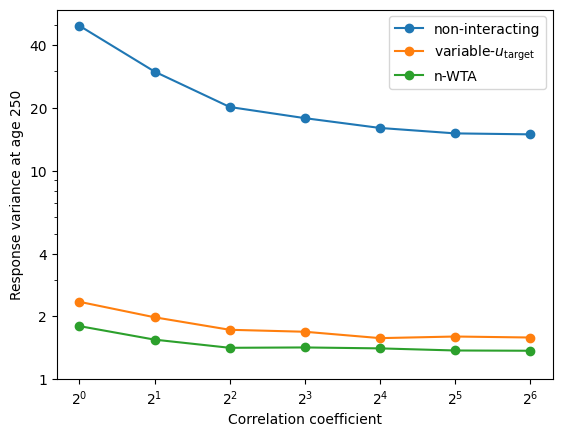

In [ ]:
coeff_list = np.array([1, 2, 4, 8, 16, 32, 64])
plt.plot(coeff_list, mean1, marker='o', label='non-interacting')
# plt.errorbar(coeff_list, mean1, yerr=std1, fmt='o', capsize=5, linestyle='None', color='C0')
plt.plot(coeff_list, mean2, marker='o', label=r'variable-$u_{\text{target}}$')
# plt.errorbar(coeff_list, mean2, yerr=std2, fmt='o', capsize=5, linestyle='None', color='C1')
plt.plot(coeff_list, mean3, marker='o', label='n-WTA')
# plt.errorbar(coeff_list, mean3, yerr=std3, fmt='o', capsize=5, linestyle='None', color='C2')

plt.xscale('log', base=2)
plt.yscale('log')
plt.yticks([1, 2, 4, 10, 20, 40], labels=['1', '2', '4', '10', '20', '40'])
plt.xlabel('Correlation coefficient')
plt.ylabel('Response variance at age 250')
plt.legend()

# plt.savefig("../figures/response_var_vs_coeff_params3.png")
plt.show()

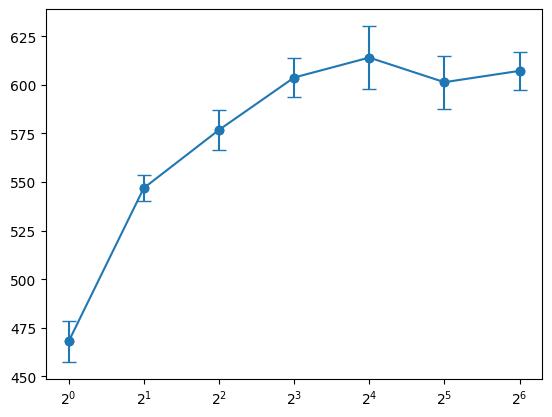

In [20]:
plt.plot(np.array([1, 2, 4, 8, 16, 32, 64]), np.mean(capa_list, axis=1), marker='o')
plt.errorbar(np.array([1, 2, 4, 8, 16, 32, 64]), np.mean(capa_list, axis=1), yerr=np.std(capa_list, axis=1), fmt='o', capsize=5, linestyle='None', color='C0')
plt.xscale('log', base=2)